# JC 主线：PyTorch MLP 与 LSTM
只使用 2024 开发数据运行两个扩展窗口验证折。2025 年不用于本阶段拟合、早停或模型选择。
MLP 输入固定长度滞后特征；LSTM 输入过去 168 小时的需求与历史天气，并拼接目标小时日历信息。

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from src.jc_baseline_models import load_weathered_prepared
from src.jc_torch_models import run_torch_cv, DEVICE
config = json.loads((ROOT / 'configs/jc_experiment.json').read_text(encoding='utf-8'))
frame = load_weathered_prepared()
frame = frame.loc[frame.index < pd.Timestamp(config['test_start_utc'])]
print('device:', DEVICE, 'development rows:', len(frame))
print('2025 is excluded from fold fitting, validation, and early stopping')

device: cuda development rows: 8784
2025 is excluded from fold fitting, validation, and early stopping


## 两个开发折训练与早停
每个折的输入缩放、天气插补及目标缩放只在该折训练集拟合；验证折用于早停。随机种子固定，GPU 可用时使用 CUDA。

In [2]:
results, predictions = run_torch_cv(frame, config)
display(pd.json_normalize(results, sep='.').T)
result_path = ROOT / 'results/metrics/jc_torch_development.json'
result_path.write_text(json.dumps({'device': str(DEVICE), 'results': results}, indent=2), encoding='utf-8')
for fold, prediction in predictions.items():
    prediction.to_csv(ROOT / f'results/metrics/jc_torch_predictions_{fold}.csv', index_label='predictor_time_utc')

,0
fold_1.mlp.n,2208
fold_1.mlp.MAE,21.672763
fold_1.mlp.RMSE,31.848154
fold_1.mlp.R2,0.925894
fold_1.mlp.train_rows,4199
fold_1.mlp.best_epoch,26
fold_1.mlp.best_validation_mse_scaled,0.115913
fold_1.mlp.epochs_run,34
fold_1.mlp.device,cuda
fold_1.lstm_168h.n,2208


## 解释
这只是开发期验证，不是最终泛化成绩。MLP 与 LSTM 的差异需要结合折间结果谨慎解释；暂不使用最终测试集，也不宣称深度模型胜过随机森林。天气历史取自历史再分析产品，其预测时可获得性限制见项目文档。

,fold,model,n,MAE,RMSE,R2,best_epoch
0,fold_1,mlp,2208,21.672763,31.848154,0.925894,26
1,fold_1,lstm_168h,2208,20.259190,30.741902,0.930953,33
2,fold_2,mlp,2039,17.404425,24.548090,0.945635,14
3,fold_2,lstm_168h,2039,16.218809,23.771995,0.949018,18


C:\Users\nahida\AppData\Local\Temp\ipykernel_63016\1764196062.py:8: UserWarning: Glyph 24320 (\N{CJK UNIFIED IDEOGRAPH-5F00}) missing from current font.
  ax.set_ylabel('MAE'); ax.set_title('PyTorch 开发折 MAE'); plt.tight_layout()
C:\Users\nahida\AppData\Local\Temp\ipykernel_63016\1764196062.py:8: UserWarning: Glyph 21457 (\N{CJK UNIFIED IDEOGRAPH-53D1}) missing from current font.
  ax.set_ylabel('MAE'); ax.set_title('PyTorch 开发折 MAE'); plt.tight_layout()
C:\Users\nahida\AppData\Local\Temp\ipykernel_63016\1764196062.py:8: UserWarning: Glyph 25240 (\N{CJK UNIFIED IDEOGRAPH-6298}) missing from current font.
  ax.set_ylabel('MAE'); ax.set_title('PyTorch 开发折 MAE'); plt.tight_layout()
C:\Users\nahida\AppData\Local\Temp\ipykernel_63016\1764196062.py:9: UserWarning: Glyph 24320 (\N{CJK UNIFIED IDEOGRAPH-5F00}) missing from current font.
  plt.savefig(ROOT / 'results/figures/jc_torch_development.png', dpi=150, bbox_inches='tight')
C:\Users\nahida\AppData\Local\Temp\ipykernel_63016\1764196062.py:

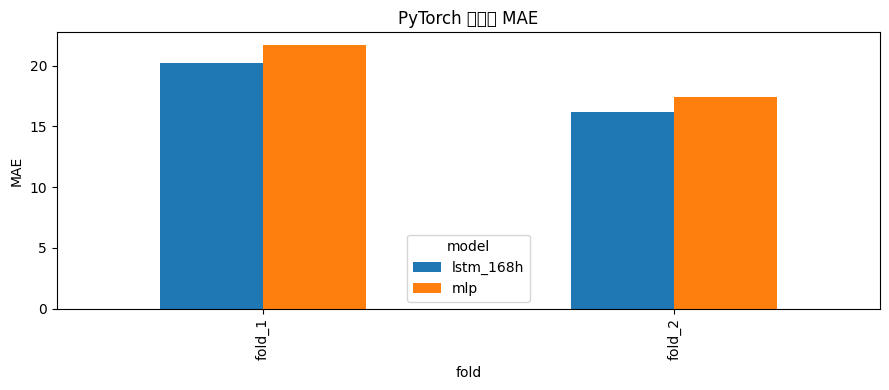

In [3]:
rows = []
for fold, fold_result in results.items():
    for model, scores in fold_result.items():
        rows.append({'fold': fold, 'model': model, **scores})
table = pd.DataFrame(rows)
display(table[['fold','model','n','MAE','RMSE','R2','best_epoch']])
ax = table.pivot(index='fold', columns='model', values='MAE').plot.bar(figsize=(9, 4))
ax.set_ylabel('MAE'); ax.set_title('PyTorch 开发折 MAE'); plt.tight_layout()
plt.savefig(ROOT / 'results/figures/jc_torch_development.png', dpi=150, bbox_inches='tight')
plt.show()